In [124]:
import os

import pandas


RESULT_PATH_PREFIX = 'sample_aris_df_threshold_gpu'


results_csv_paths = [
    subpath
    for subpath in os.listdir()
    if subpath.startswith(RESULT_PATH_PREFIX)
]

results_csvs = [
    pandas.read_csv(subpath)
    for subpath in results_csv_paths
]

In [125]:
for path, csv in zip(results_csv_paths, results_csvs):
    threshold = path.split('_')[5]
    run = path.split('_')[-1].split('.')[0]
    csv['threshold'] = float(threshold)
    csv['run'] = int(run)

In [126]:
full_result_csv = pandas.concat(results_csvs, ignore_index=True)

In [127]:
full_result_csv.columns

Index(['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676', 'threshold', 'run'],
      dtype='object')

In [128]:
FULL_SAMPLE_COLS = ['151673', '151672', '151507', '151508', '151669', '151509', '151671',
       '151510', '151670', '151674', '151675', '151676']

In [129]:
full_result_csv.shape

(890, 14)

In [130]:
full_result_csv = full_result_csv.groupby(['threshold', 'run'])[FULL_SAMPLE_COLS].median().reset_index()
full_result_csv_grouped = full_result_csv.groupby(['threshold'])[FULL_SAMPLE_COLS].max().reset_index()

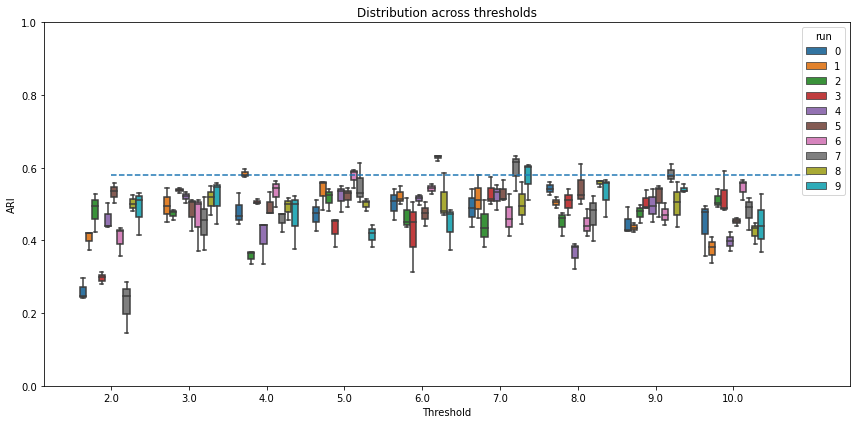

In [133]:
import matplotlib.pyplot as plt
import seaborn as sns


TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]


df_long = full_result_csv.melt(
    id_vars=["threshold", "run"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value", hue='run')

plt.title("Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")
plt.ylim([0, 1])

plt.hlines(0.58, 0 , 9, linestyle='--')

plt.tight_layout()
plt.show()

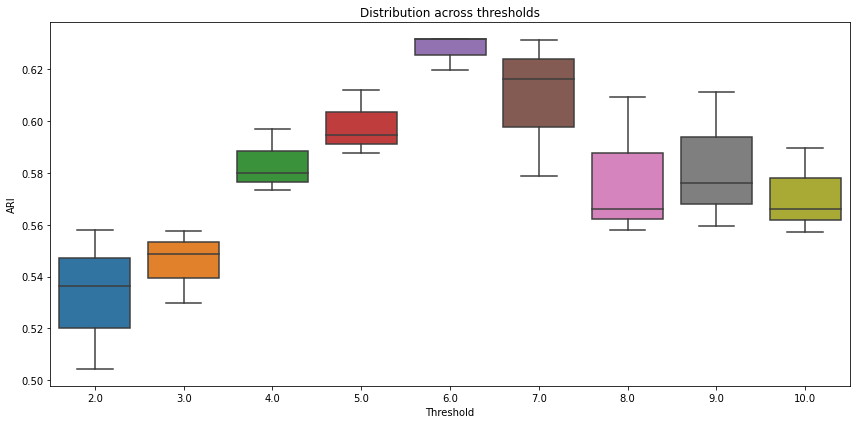

In [134]:
TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

current_results = full_result_csv_grouped 
df_long = current_results.melt(
    id_vars=["threshold"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('threshold')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="threshold", y="value")

plt.title(f"Distribution across thresholds")
plt.xlabel("Threshold")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

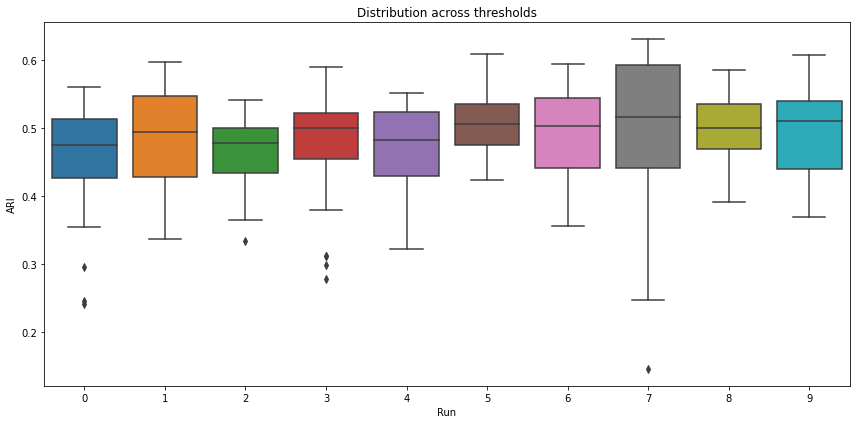

In [135]:
TEST_SAMPLES = [
    '151507',
    '151672',
    '151673',
]

current_results = full_result_csv 
df_long = current_results.melt(
    id_vars=["run"],
    value_vars=TEST_SAMPLES,
    var_name="sample",
    value_name="value"
)


df_long = df_long.sort_values('run')


# plot
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_long, x="run", y="value")

plt.title(f"Distribution across thresholds")
plt.xlabel("Run")
plt.ylabel("ARI")

plt.tight_layout()
plt.show()

In [99]:
NON_TEST_SAMPLES = [sample for sample in FULL_SAMPLE_COLS if sample not in TEST_SAMPLES]

In [100]:
df_long_run_train = current_results.groupby(['run', 'threshold'])[NON_TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()
df_long_run_test = current_results.groupby(['run', 'threshold'])[TEST_SAMPLES].mean().mean(axis=1).to_frame().reset_index()

In [101]:
df_long_run_train

,run,threshold,0
0,0,2.0,0.257856
1,0,4.0,0.398216
2,0,5.0,0.409656
3,0,6.0,0.505519
4,0,7.0,0.470981
...,...,...,...
84,9,6.0,0.431350
85,9,7.0,0.507868
86,9,8.0,0.530946
87,9,9.0,0.464469


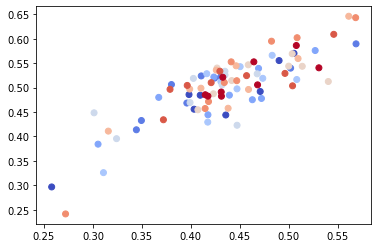

In [102]:
plt.scatter(
    df_long_run_train[0], df_long_run_test[0], c=df_long_run_train['run'], cmap='coolwarm')

In [103]:
model_prefix = 'DLPFC_CELLOHOOD_MODEL_GPU'


model_paths = [
    path 
    for path in os.listdir()
    if path.startswith(model_prefix)
]

In [104]:
histories = []


for path in model_paths:
    threshold = float(path.split('_')[4])
    run = int(path.split('_')[5])
    history_path = os.path.join(path, 'model_history.df')
    history = pandas.read_csv(history_path)
    history['threshold'] = threshold
    history['run'] = run
    histories.append(history)

In [105]:
histories_df = pandas.concat(histories, ignore_index=True)

In [106]:
histories_df_last = histories_df[histories_df['Unnamed: 0'] == 99]

(array([ 9.,  4.,  7., 11., 18., 11.,  8.,  0., 12., 10.]),
 array([0.02404674, 0.05207788, 0.08010901, 0.10814015, 0.13617129,
        0.16420242, 0.19223356, 0.22026469, 0.24829583, 0.27632696,
        0.3043581 ]),
 <BarContainer object of 10 artists>)

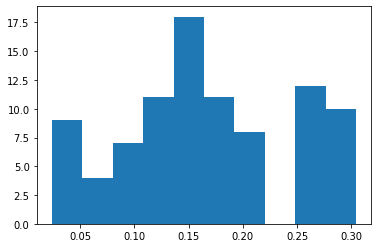

In [107]:
plt.hist(histories_df_last['loss'])

In [108]:
histories_df_last = histories_df_last.sort_values(['threshold', 'run'])

In [61]:
#df_long = df_long.sort_values(['threshold', 'run'])

In [62]:
histories_df_last.shape

(90, 5)

In [63]:
grouped_results = full_result_csv.groupby(['threshold', 'run'])[TEST_SAMPLES].mean().reset_index()

In [64]:
total_with_loss = pandas.merge(grouped_results, histories_df_last)

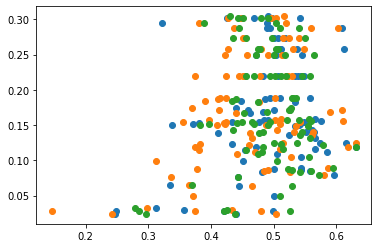

In [65]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['loss'])

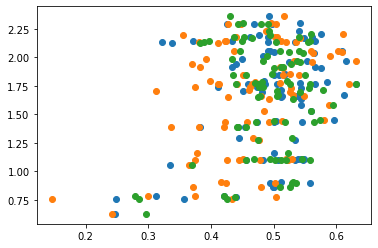

In [66]:
for sample in TEST_SAMPLES:
    plt.scatter(total_with_loss[sample], total_with_loss['ent'])